# Exercise 1 (10 points)

In this exercise, we will practice how to test a function in Python. Imagine you have a function `normalize_data()` that takes in a `pandas` DataFrame and normalizes each column (scales the data so that the values in each column are between 0 and 1). You want to test this function to ensure it works correctly.


```
import pandas as pd

def normalize_data(df):
    return (df - df.min()) / (df.max() - df.min())
```

Write a test function using `assert` statements to verify that:

- Each column's minimum value is 0 and maximum value is 1 after normalization.
- The function raises an error if the input is not a DataFrame.
- The function does not alter the original DataFrame.



In [1]:
import pandas as pd

def normalize_data(df):
    # Added a check so the function raises a clear error for bad input
    if not isinstance(df, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame")
    return (df - df.min()) / (df.max() - df.min())


def test_normalize_data():
    # Sample data to test with
    df = pd.DataFrame({
        "A": [10, 20, 30, 40],
        "B": [5, 15, 25, 100]
    })

    # Save a copy so we can check the original is not changed
    original = df.copy()

    result = normalize_data(df)

    # Test 1: each column has min 0 and max 1
    for col in result.columns:
        assert result[col].min() == 0, f"{col} min is not 0"
        assert result[col].max() == 1, f"{col} max is not 1"

    # Test 2: an error is raised if the input is not a DataFrame
    error_raised = False
    try:
        normalize_data([1, 2, 3])
    except TypeError:
        error_raised = True
    assert error_raised, "No error raised for a list input"

    # Test 3: the original DataFrame was not changed
    assert df.equals(original), "The original DataFrame was changed"

    print("All tests passed!")


test_normalize_data()

All tests passed!


# Exercise 2

In this exercise, we will practice data visualiation with the `credit_card_transactions_India.csv` data file. This dataset contains insights into a collection of credit card transactions made in India, offering a comprehensive look at the spending habits of Indians across the nation. From the Gender and Card type used to carry out each transaction, to which city saw the highest amount of spending and even what kind of expenses were made, this dataset paints an overall picture about how money is being spent in India today. A brief description of the features is shown below.

- `City`: The city in which the transaction took place. 
- `Date`: The date of the transaction. 
- `Card Type`: The type of credit card used for the transaction.
- `Exp Type`: The type of expense associated with the transaction. 
- `Gender`: The gender of the cardholder. 
- `Amount`: The amount of the transaction.

### Exercise 2(a) (2 points)

Load `pandas`, `matplotlib`, and `seaborn`.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


### Exercise 2(b) (2 points)

Read the `credit_card_transactions_India.csv` data file and create a data frame called `credit`.

In [4]:
# Read the CSV file into a data frame called credit
credit = pd.read_csv("credit_card_transactions_India.csv")

# Show the first few rows to confirm it loaded
print(credit.head())


   index                   City       Date  Card Type Exp Type Gender  Amount
0      0           Delhi, India  29-Oct-14       Gold    Bills      F   82475
1      1  Greater Mumbai, India  22-Aug-14   Platinum    Bills      F   32555
2      2       Bengaluru, India  27-Aug-14     Silver    Bills      F  101738
3      3  Greater Mumbai, India  12-Apr-14  Signature    Bills      F  123424
4      4       Bengaluru, India   5-May-15       Gold    Bills      F  171574


### Exercise 2(c) (3 points)

Convert `Date` to `date-time` format.

In [6]:
# Convert the Date column to datetime format
credit["Date"] = pd.to_datetime(credit["Date"])

# Check that the data type changed to datetime64
credit.dtypes

index                 int64
City                    str
Date         datetime64[us]
Card Type               str
Exp Type                str
Gender                  str
Amount                int64
dtype: object

### Exercise 2(d) (3 points)

Select credit card transaction in `Delhi, India` and create a data frame called `Delhi`.

In [8]:
# Keep only the rows where City is "Delhi, India"
Delhi = credit[credit["City"] == "Delhi, India"]

# Show the first few rows and the row count
print(Delhi.shape)
print(Delhi.head())

(3482, 7)
   index          City       Date Card Type Exp Type Gender  Amount
0      0  Delhi, India 2014-10-29      Gold    Bills      F   82475
5      5  Delhi, India 2014-09-08    Silver    Bills      F  100036
6      6  Delhi, India 2015-02-24      Gold    Bills      F  143250
8      8  Delhi, India 2014-03-28    Silver    Bills      F  192247
9      9  Delhi, India 2014-09-01  Platinum    Bills      F   67932


### Exercise 2(e) (3 points)

Create a frequency table of `Card Type` of the `Delhi` data frame.

In [9]:
# Count how many Delhi transactions used each card type
Delhi["Card Type"].value_counts()

Card Type
Silver       956
Signature    872
Gold         863
Platinum     791
Name: count, dtype: int64

### Exercise 2(e) (6 points)

Create a time-series plot of `Amount` based on the different `Card Type`.

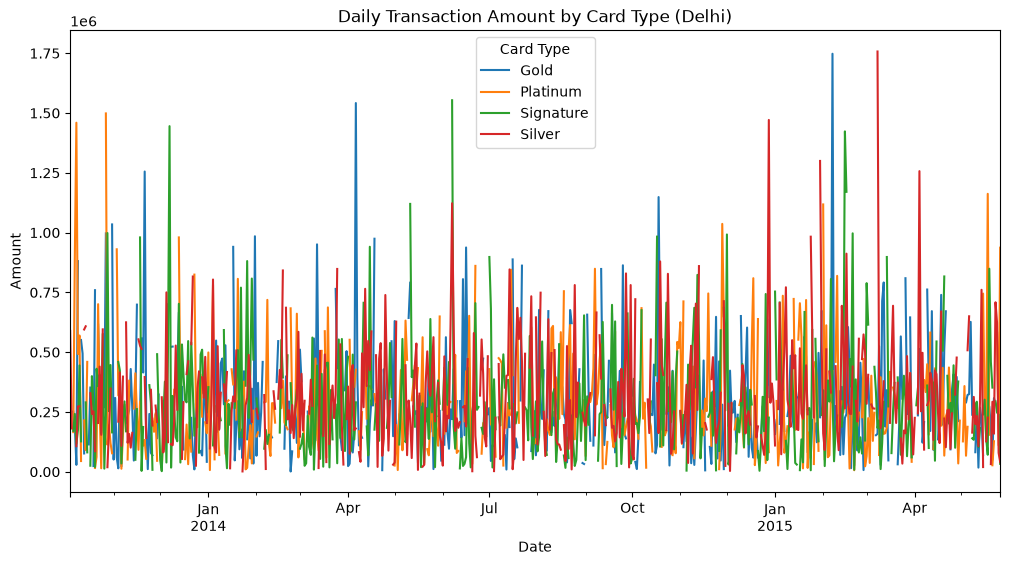

In [10]:
import matplotlib.pyplot as plt

# Total amount spent per day for each card type (Delhi data)
daily = Delhi.groupby(["Date", "Card Type"])["Amount"].sum().unstack()

# Plot one line per card type
daily.plot(figsize=(12, 6))
plt.title("Daily Transaction Amount by Card Type (Delhi)")
plt.xlabel("Date")
plt.ylabel("Amount")
plt.legend(title="Card Type")
plt.show()

### Exercise 2(f) (6 points)

Create a time-series plot of `Amount` based on `Gender`.

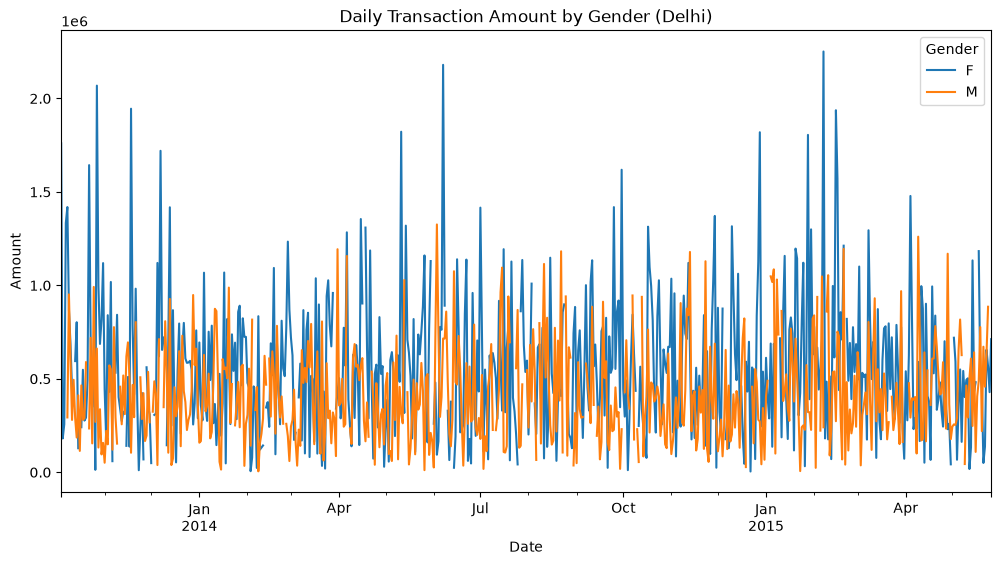

In [11]:
import matplotlib.pyplot as plt

# Total amount spent per day for each gender (Delhi data)
daily_gender = Delhi.groupby(["Date", "Gender"])["Amount"].sum().unstack()

# Plot one line per gender
daily_gender.plot(figsize=(12, 6))
plt.title("Daily Transaction Amount by Gender (Delhi)")
plt.xlabel("Date")
plt.ylabel("Amount")
plt.legend(title="Gender")
plt.show()

# Exercise 3 (10 points)

Conceptual question on testing code in applied data science.

A teammate tells you: *"My data-cleaning and modeling pipeline runs without errors and the model's accuracy is 95%, so the code must be correct and I don't need to write tests."*

Do you agree? In your answer:

1. Explain why a pipeline that runs without errors and reports a high accuracy does not guarantee that the code is correct. Give at least two examples of silent bugs that could occur in a data science project (e.g., data leakage, incorrect joins, mishandled missing values).
2. Explain why testing data science code is harder than testing traditional software, and name two practices that help (e.g., fixing random seeds, using small hand-made fixtures, testing properties/invariants rather than exact values).

I disagree.

**1. Running without errors doesn't mean the code is correct.**

Python only stops when something is technically broken, not when the logic is wrong. A pipeline can run cleanly and still give misleading results. For example:

- **Data leakage:** if I scale or fill missing values using the whole dataset before splitting into train and test, the model gets a peek at the test data, so the 95% accuracy is inflated.
- **Mishandled missing values:** if I fill missing values with 0 when 0 is a real value (like income or age), the data quietly becomes wrong, but nothing crashes.

Also, 95% accuracy can be misleading on its own. If 95% of the rows belong to one class, a model that always guesses that class gets 95% without learning anything.

**2. Testing data science code is harder than regular software.**

In regular software, I usually know the exact right answer to check against. In data science, the data changes, models use randomness, and results are approximate, so there often isn't one exact "correct" output. Two practices that help:

- **Fix random seeds** (like `random_state=42`) so results are the same every run and I can compare them.
- **Test properties instead of exact values**, like checking that normalized columns are between 0 and 1, there are no missing values after cleaning, or the row count didn't change after a join. ;-)